# 07 — Machine Learning for Steam Market Segmentation

## Business Objective

The objective of this analysis is to identify distinct
market-positioning profiles among Steam games using
unsupervised machine learning.

Rather than defining segments manually, clustering will
be used to identify groups of games with similar
characteristics.

The analysis will then examine how these segments differ
in terms of market performance, particularly player reach
and satisfaction.

### Business Question

**Which distinct market-positioning profiles emerge on
Steam, and how do they differ in reach and player
satisfaction?**

The goal is to provide a segmentation that could help
publishers, developers or marketing teams better understand
the competitive landscape and position a game relative to
comparable products.

## 1. Dataset and Feature Audit

Before building the clustering model, the available
features are reviewed to determine:

- which variables describe market positioning,
- which variables represent market performance,
- which variables have sufficient data coverage,
- and which variables require preprocessing.

This distinction is important because performance
indicators may be more useful for evaluating the
resulting segments than for defining them directly.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Define project path
project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

data_path = (
    project_root
    / "data/processed/games_cleaned_march2025.csv"
)

# Load historical Steam dataset
df_ml = pd.read_csv(data_path)

print("Dataset shape:", df_ml.shape)
print("\nColumns:")
print(df_ml.columns.tolist())

Dataset shape: (94948, 48)

Columns:
['appid', 'name', 'release_date', 'required_age', 'price', 'dlc_count', 'header_image', 'windows', 'mac', 'linux', 'metacritic_score', 'achievements', 'recommendations', 'supported_languages', 'full_audio_languages', 'developers', 'publishers', 'categories', 'genres', 'positive', 'negative', 'estimated_owners', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'discount', 'peak_ccu', 'tags', 'pct_pos_total', 'num_reviews_total', 'pct_pos_recent', 'num_reviews_recent', 'release_year', 'owners_lower', 'owners_upper', 'estimated_owners_midpoint', 'is_free', 'price_band', 'recent_reception_gap', 'has_lifetime_playtime', 'has_recent_playtime', 'has_peak_ccu', 'tag_names', 'name_was_missing', 'average_playtime_hours', 'median_playtime_hours', 'extreme_playtime']


In [2]:
# Build a feature audit table

feature_audit = pd.DataFrame({
    "dtype": df_ml.dtypes.astype(str),
    "non_null": df_ml.notna().sum(),
    "missing_pct": (df_ml.isna().mean() * 100).round(2),
    "unique_values": df_ml.nunique(dropna=True)
})

feature_audit = feature_audit.sort_values(
    "missing_pct",
    ascending=True
)

display(feature_audit)

,dtype,non_null,missing_pct,unique_values
appid,int64,94948,0.00,94948
average_playtime_forever,int64,94948,0.00,1853
median_playtime_hours,float64,94948,0.00,1641
median_playtime_forever,int64,94948,0.00,1641
median_playtime_2weeks,int64,94948,0.00,421
discount,int64,94948,0.00,86
peak_ccu,int64,94948,0.00,1181
tags,str,94948,0.00,70499
estimated_owners,str,94948,0.00,15
release_year,int64,94948,0.00,27


In [3]:
# Inspect potential clustering features

candidate_features = [
    "price",
    "is_free",
    "required_age",
    "dlc_count",
    "achievements",
    "windows",
    "mac",
    "linux",
    "release_year",
    "discount"
]

display(
    df_ml[candidate_features]
    .describe(include="all")
    .T
)

print("\nFREE VS PAID")
display(
    df_ml["is_free"].value_counts(dropna=False)
)

print("\nREQUIRED AGE")
display(
    df_ml["required_age"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRELEASE YEARS")
print("Min:", df_ml["release_year"].min())
print("Max:", df_ml["release_year"].max())

print("\nEXAMPLES OF GENRES")
display(
    df_ml[
        ["name", "genres"]
    ].head(10)
)

print("\nEXAMPLES OF SUPPORTED LANGUAGES")
display(
    df_ml[
        ["name", "supported_languages", "full_audio_languages"]
    ].head(5)
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,94948.0,NaN,NaN,NaN,6.911444,13.071148,0.0,0.99,3.99,9.99,999.98
is_free,94948,2,False,75528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
required_age,94947.0,NaN,NaN,NaN,0.178299,1.701333,0.0,0.0,0.0,0.0,21.0
dlc_count,94948.0,NaN,NaN,NaN,0.563203,14.915685,0.0,0.0,0.0,0.0,3427.0
achievements,94948.0,NaN,NaN,NaN,19.543729,159.798834,0.0,0.0,2.0,19.0,9821.0
windows,94948,2,True,94918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mac,94948,2,False,77475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
linux,94948,2,False,82290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,94948.0,NaN,NaN,NaN,2020.892731,3.074266,1997.0,2019.0,2022.0,2024.0,2025.0
discount,94948.0,NaN,NaN,NaN,4.307094,16.111535,0.0,0.0,0.0,0.0,100.0



FREE VS PAID


is_free
False    75528
True     19420
Name: count, dtype: int64


REQUIRED AGE


required_age
0.0     93891
1.0         2
3.0         7
6.0         4
7.0         5
10.0       27
12.0       21
13.0      156
14.0        1
15.0        3
16.0       31
17.0      645
18.0      152
20.0        1
21.0        1
NaN         1
Name: count, dtype: int64


RELEASE YEARS
Min: 1997
Max: 2025

EXAMPLES OF GENRES


,name,genres
0,Counter-Strike 2,"[""Action"", ""Free To Play""]"
1,PUBG: BATTLEGROUNDS,"[""Action"", ""Adventure"", ""Massively Multiplayer..."
2,Dota 2,"[""Action"", ""Strategy"", ""Free To Play""]"
3,Grand Theft Auto V Legacy,"[""Action"", ""Adventure""]"
4,Tom Clancy's Rainbow Six® Siege,"[""Action""]"
5,Tom Clancy's Rainbow Six® Siege,"[""Action""]"
6,Tom Clancy's Rainbow Six® Siege,"[""Action""]"
7,Tom Clancy's Rainbow Six® Siege,"[""Action""]"
8,Tom Clancy's Rainbow Six® Siege,"[""Action""]"
9,Team Fortress 2,"[""Action"", ""Free To Play""]"



EXAMPLES OF SUPPORTED LANGUAGES


,name,supported_languages,full_audio_languages
0,Counter-Strike 2,"[""Czech"", ""Danish"", ""Dutch"", ""English"", ""Finni...","[""English"", ""Indonesian""]"
1,PUBG: BATTLEGROUNDS,"[""English"", ""Korean"", ""Simplified Chinese"", ""F...",[]
2,Dota 2,"[""Bulgarian"", ""Czech"", ""Danish"", ""Dutch"", ""Eng...","[""English"", ""Korean"", ""Simplified Chinese"", ""V..."
3,Grand Theft Auto V Legacy,"[""English"", ""French"", ""Italian"", ""German"", ""Sp...","[""English"", ""Spanish - Latin America""]"
4,Tom Clancy's Rainbow Six® Siege,"[""English"", ""French"", ""Italian"", ""German"", ""Sp...","[""English"", ""French"", ""Italian"", ""German"", ""Sp..."


## 2. Feature Engineering for Market Positioning

The initial feature audit showed that some variables
provide very little discriminatory information, while
others require transformation before clustering.

The following preprocessing focuses on stable game
characteristics related to market positioning.

Derived features include:
- game age at the 2025 historical snapshot,
- number of supported languages,
- number of full-audio languages,
- and structured genre information.



In [4]:
import ast

df_seg = df_ml.copy()

# Convert string representations of lists back to Python lists
def parse_list(value):
    if isinstance(value, list):
        return value
    
    if pd.isna(value):
        return []
    
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []


df_seg["genres_list"] = df_seg["genres"].apply(parse_list)

df_seg["supported_languages_list"] = (
    df_seg["supported_languages"].apply(parse_list)
)

df_seg["full_audio_languages_list"] = (
    df_seg["full_audio_languages"].apply(parse_list)
)


# Create interpretable derived features
df_seg["game_age"] = 2025 - df_seg["release_year"]

df_seg["supported_languages_count"] = (
    df_seg["supported_languages_list"].apply(len)
)

df_seg["full_audio_languages_count"] = (
    df_seg["full_audio_languages_list"].apply(len)
)


# Inspect derived numerical features
derived_features = [
    "game_age",
    "supported_languages_count",
    "full_audio_languages_count"
]

display(
    df_seg[derived_features]
    .describe()
    .T
)

print("\nMOST COMMON GENRES")

genre_counts = (
    df_seg["genres_list"]
    .explode()
    .value_counts()
)

display(genre_counts.head(15))

,count,mean,std,min,25%,50%,75%,max
game_age,94948.0,4.107269,3.074266,0.0,1.0,3.0,6.0,28.0
supported_languages_count,94948.0,4.953448,12.952921,0.0,1.0,1.0,4.0,103.0
full_audio_languages_count,94948.0,1.969952,10.639013,0.0,0.0,0.0,1.0,103.0



MOST COMMON GENRES


genres_list
Indie                    63228
Casual                   38719
Action                   36894
Adventure                35495
Simulation               18596
Strategy                 17380
RPG                      16350
Early Access              9121
Free To Play              8873
Sports                    3948
Racing                    3302
Massively Multiplayer     2129
Utilities                  856
Design & Illustration      494
Violent                    429
Name: count, dtype: int64

In [5]:
# Audit language-count outliers before using them in clustering

print("TOP SUPPORTED LANGUAGE COUNTS")

display(
    df_seg[
        [
            "name",
            "supported_languages_count",
            "supported_languages_list"
        ]
    ]
    .sort_values(
        "supported_languages_count",
        ascending=False
    )
    .head(10)
)

print("\nTOP FULL-AUDIO LANGUAGE COUNTS")

display(
    df_seg[
        [
            "name",
            "full_audio_languages_count",
            "full_audio_languages_list"
        ]
    ]
    .sort_values(
        "full_audio_languages_count",
        ascending=False
    )
    .head(10)
)

TOP SUPPORTED LANGUAGE COUNTS


,name,supported_languages_count,supported_languages_list
23800,"Oh, you touch my balls ( ͡° ͜ʖ ͡°)",103,"[English, French, Italian, German, Spanish - S..."
46612,COSMIC HOLES,103,"[English, French, Italian, German, Spanish - S..."
58533,Poly Memory: Animals,103,"[English, French, Italian, German, Spanish - S..."
34295,BACKROOMS THE COMPANY,103,"[English, French, Italian, German, Spanish - S..."
34285,Hentai SpaceSuit,103,"[English, French, Italian, German, Spanish - S..."
63017,Dream celestial body,103,"[English, French, Italian, German, Spanish - S..."
46690,Data mining,103,"[English, French, Italian, German, Spanish - S..."
46739,aMAZE Gears 2,103,"[English, French, Italian, German, Spanish - S..."
13217,Chill,103,"[English, French, Italian, German, Spanish - S..."
80785,GraFi St.Patrick,103,"[English, French, Italian, German, Spanish - S..."



TOP FULL-AUDIO LANGUAGE COUNTS


,name,full_audio_languages_count,full_audio_languages_list
8586,aMAZE,103,"[English, French, Italian, German, Spanish - S..."
27931,aMAZE Frozen,103,"[English, French, Italian, German, Spanish - S..."
17484,AccrO,103,"[English, French, Italian, German, Spanish - S..."
40346,zzzzz,103,"[English, French, Italian, German, Spanish - S..."
62597,Fission,103,"[English, French, Italian, German, Spanish - S..."
36173,Hentai Oni,103,"[English, French, Italian, German, Spanish - S..."
36169,PSIONIC,103,"[English, French, Italian, German, Spanish - S..."
52838,SEARCH ALL - SNAKES,103,"[English, French, Italian, German, Spanish - S..."
56113,Hentai Jigsaw Puzzle Collection: Spring Edition,103,"[English, French, Italian, German, Spanish - S..."
26897,Hentai Shooter 2: World Tour,103,"[English, French, Italian, German, Spanish - S..."


In [6]:
# Check whether is_free adds information beyond price == 0

free_check = pd.crosstab(
    df_seg["price"].eq(0),
    df_seg["is_free"],
    rownames=["price_is_zero"],
    colnames=["is_free"]
)

display(free_check)

is_free,False,True
price_is_zero,,
False,75528,0
True,0,19420


### Selected Market-Positioning Features

Based on data coverage, variability and business relevance,
the clustering focuses on stable characteristics describing
how games are positioned on Steam.

Performance variables such as estimated reach, reviews,
player satisfaction and engagement are intentionally
excluded from cluster construction.

They will instead be used later to compare and interpret
the resulting market segments.

In [7]:
# Create binary genre-positioning features

selected_genres = [
    "Indie",
    "Casual",
    "Action",
    "Adventure",
    "Simulation",
    "Strategy",
    "RPG"
]

for genre in selected_genres:
    column_name = "genre_" + genre.lower().replace(" ", "_")
    
    df_seg[column_name] = df_seg["genres_list"].apply(
        lambda genres: int(genre in genres)
    )

# Early Access is treated as a development-status feature
df_seg["early_access"] = df_seg["genres_list"].apply(
    lambda genres: int("Early Access" in genres)
)

genre_features = [
    "genre_indie",
    "genre_casual",
    "genre_action",
    "genre_adventure",
    "genre_simulation",
    "genre_strategy",
    "genre_rpg",
    "early_access"
]

display(
    df_seg[genre_features]
    .mean()
    .mul(100)
    .round(2)
    .rename("share_pct")
    .to_frame()
)

,share_pct
genre_indie,66.59
genre_casual,40.78
genre_action,38.86
genre_adventure,37.38
genre_simulation,19.59
genre_strategy,18.30
genre_rpg,17.22
early_access,9.61


## 3. Clustering Feature Matrix

The clustering matrix contains only characteristics
related to game positioning and product structure.

Performance variables are excluded so that reach,
satisfaction and engagement can later be used as
independent profiling metrics.

Highly skewed numerical variables are transformed
using `log1p` before scaling.

In [11]:
from sklearn.preprocessing import StandardScaler

# Log-transform highly skewed numerical variables
df_seg["log_price"] = np.log1p(df_seg["price"])
df_seg["log_dlc_count"] = np.log1p(df_seg["dlc_count"])
df_seg["log_achievements"] = np.log1p(df_seg["achievements"])

# Number of supported desktop platforms
df_seg["platform_count"] = (
    df_seg["windows"].astype(int)
    + df_seg["mac"].astype(int)
    + df_seg["linux"].astype(int)
)

# Numerical features
numeric_features = [
    "log_price",
    "game_age",
    "log_dlc_count",
    "log_achievements",
    "platform_count"
]

# Binary positioning features
binary_features = [
    "genre_indie",
    "genre_casual",
    "genre_action",
    "genre_adventure",
    "genre_simulation",
    "genre_strategy",
    "genre_rpg",
    "early_access"
]

# Build feature matrix
X = df_seg[numeric_features + binary_features].copy()

print("Feature matrix shape:", X.shape)
print("Missing values:", X.isna().sum().sum())

display(X.describe().T)

Feature matrix shape: (94948, 13)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
log_price,94948.0,1.511648,1.057340,0.0,0.688135,1.607436,2.396986,6.908735
game_age,94948.0,4.107269,3.074266,0.0,1.000000,3.000000,6.000000,28.000000
log_dlc_count,94948.0,0.154803,0.441284,0.0,0.000000,0.000000,0.000000,8.139732
log_achievements,94948.0,1.523444,1.616627,0.0,0.000000,1.098612,2.995732,9.192380
platform_count,94948.0,1.317026,0.643953,1.0,1.000000,1.000000,1.000000,3.000000
genre_indie,94948.0,0.665922,0.471669,0.0,0.000000,1.000000,1.000000,1.000000
genre_casual,94948.0,0.407792,0.491427,0.0,0.000000,0.000000,1.000000,1.000000
genre_action,94948.0,0.388571,0.487428,0.0,0.000000,0.000000,1.000000,1.000000
genre_adventure,94948.0,0.373836,0.483823,0.0,0.000000,0.000000,1.000000,1.000000
genre_simulation,94948.0,0.195855,0.396859,0.0,0.000000,0.000000,0.000000,1.000000


In [12]:
# Scale numerical features only

scaler = StandardScaler()

X_scaled = X.copy()

X_scaled[numeric_features] = scaler.fit_transform(
    X[numeric_features]
)

print("Scaled feature matrix shape:", X_scaled.shape)

display(
    X_scaled[numeric_features]
    .describe()
    .round(2)
)

Scaled feature matrix shape: (94948, 13)


,log_price,game_age,log_dlc_count,log_achievements,platform_count
count,94948.00,94948.00,94948.00,94948.00,94948.00
mean,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.43,-1.34,-0.35,-0.94,-0.49
25%,-0.78,-1.01,-0.35,-0.94,-0.49
50%,0.09,-0.36,-0.35,-0.26,-0.49
75%,0.84,0.62,-0.35,0.91,-0.49
max,5.10,7.77,18.09,4.74,2.61


In [13]:
# Inspect DLC distribution and extreme values

print("Games with at least one DLC:")
games_with_dlc = (df_seg["dlc_count"] > 0).sum()

print(
    games_with_dlc,
    f"({games_with_dlc / len(df_seg) * 100:.2f}%)"
)

print("\nDLC COUNT QUANTILES")

display(
    df_seg["dlc_count"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
    )
)

print("\nGAMES WITH THE HIGHEST DLC COUNTS")

display(
    df_seg[
        ["name", "dlc_count"]
    ]
    .sort_values(
        "dlc_count",
        ascending=False
    )
    .head(10)
)

Games with at least one DLC:
14253 (15.01%)

DLC COUNT QUANTILES


0.500       0.000
0.750       0.000
0.900       1.000
0.950       2.000
0.990       7.000
0.995      13.000
0.999      48.053
1.000    3427.000
Name: dlc_count, dtype: float64


GAMES WITH THE HIGHEST DLC COUNTS


,name,dlc_count
8284,Fantasy Grounds VTT,3427
6966,Fantasy Grounds Classic,2004
1405,Rocksmith® 2014 Edition REMASTERED LEARN & PLAY,1191
58680,RPG Maker MV,954
61955,RPG Maker MZ,767
1180,Train Simulator Classic 2024,765
2950,DEAD OR ALIVE 6,461
61248,RPG Maker VX Ace,448
8694,Trainz Railroad Simulator 2022,316
21249,Trainz Plus,311


### Treatment of Extreme DLC Counts

DLC counts are highly skewed.

While 95% of games have two DLCs or fewer and 99.5%
have 13 or fewer, a very small number of titles contain
hundreds or even thousands of DLC entries.

These observations appear to be legitimate but are
extreme relative to the broader market.

To prevent rare cases from dominating Euclidean
distances in K-Means, DLC counts are capped at the
99.5th percentile for clustering purposes.

Original values are preserved in the source dataset.

In [14]:
# Cap extreme DLC values at the 99.5th percentile

dlc_cap = df_seg["dlc_count"].quantile(0.995)

df_seg["dlc_count_clipped"] = (
    df_seg["dlc_count"].clip(upper=dlc_cap)
)

df_seg["log_dlc_count"] = np.log1p(
    df_seg["dlc_count_clipped"]
)

print("DLC cap:", dlc_cap)
print(
    "Games affected:",
    (df_seg["dlc_count"] > dlc_cap).sum()
)

DLC cap: 13.0
Games affected: 446


In [15]:
# Rebuild feature matrix after DLC outlier treatment

X = df_seg[numeric_features + binary_features].copy()

X_scaled = X.copy()

X_scaled[numeric_features] = scaler.fit_transform(
    X[numeric_features]
)

print("Final feature matrix:", X_scaled.shape)
print("Missing values:", X_scaled.isna().sum().sum())

display(
    X_scaled[numeric_features]
    .describe()
    .round(2)
)

Final feature matrix: (94948, 13)
Missing values: 0


,log_price,game_age,log_dlc_count,log_achievements,platform_count
count,94948.00,94948.00,94948.00,94948.00,94948.00
mean,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.43,-1.34,-0.37,-0.94,-0.49
25%,-0.78,-1.01,-0.37,-0.94,-0.49
50%,0.09,-0.36,-0.37,-0.26,-0.49
75%,0.84,0.62,-0.37,0.91,-0.49
max,5.10,7.77,6.05,4.74,2.61


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette
    })

clustering_results = pd.DataFrame(results)

display(clustering_results)

,k,inertia,silhouette_score
0,2,510492.918292,0.189206
1,3,446837.229546,0.187058
2,4,395597.563752,0.184540
3,5,358306.461835,0.167369
4,6,332008.942874,0.162983
5,7,315051.807532,0.164768
6,8,302618.063740,0.158025


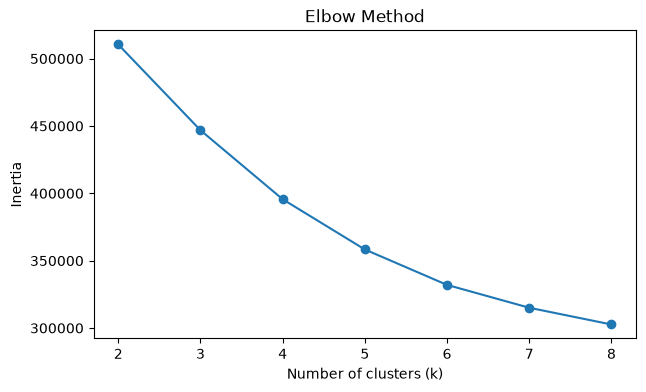

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(
    clustering_results["k"],
    clustering_results["inertia"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

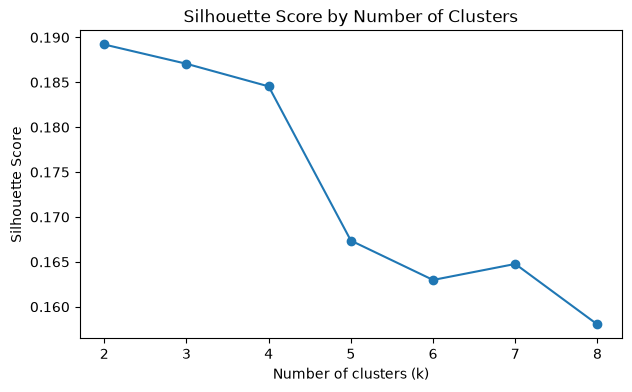

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(
    clustering_results["k"],
    clustering_results["silhouette_score"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.show()

### Candidate Number of Clusters

The evaluation does not reveal a single dominant
number of clusters.

The highest silhouette score is obtained with two
clusters (0.189), but the scores for three and four
clusters remain very similar.

The elbow curve continues to improve substantially
up to approximately four clusters, while the silhouette
score decreases more noticeably from five clusters onward.

For this reason, four clusters are selected as the
main candidate for further profiling.

The final choice will also depend on cluster size,
stability and business interpretability.

In [19]:
# Fit candidate K-Means model with 4 clusters

kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df_seg["cluster_4"] = kmeans_4.fit_predict(X_scaled)

# Cluster sizes
cluster_sizes = (
    df_seg["cluster_4"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="games")
)

cluster_sizes["share_pct"] = (
    cluster_sizes["games"]
    / len(df_seg)
    * 100
).round(2)

display(cluster_sizes)

,cluster,games,share_pct
0,0,45303,47.71
1,1,30908,32.55
2,2,13948,14.69
3,3,4789,5.04


In [20]:
# Numerical and commercial profile of each cluster

cluster_profile = (
    df_seg
    .groupby("cluster_4")
    .agg(
        games=("appid", "count"),
        median_price=("price", "median"),
        free_share=("is_free", "mean"),
        median_game_age=("game_age", "median"),
        dlc_share=("dlc_count", lambda x: (x > 0).mean()),
        median_achievements=("achievements", "median"),
        mean_platform_count=("platform_count", "mean"),
        early_access_share=("early_access", "mean")
    )
)

percentage_columns = [
    "free_share",
    "dlc_share",
    "early_access_share"
]

cluster_profile[percentage_columns] = (
    cluster_profile[percentage_columns] * 100
)

display(cluster_profile.round(2))

,games,median_price,free_share,median_game_age,dlc_share,median_achievements,mean_platform_count,early_access_share
cluster_4,,,,,,,,
0,45303,1.99,31.32,3.0,3.93,0.0,1.07,11.99
1,30908,4.99,8.99,3.0,14.59,19.0,1.08,8.27
2,13948,4.99,11.56,6.0,22.75,13.0,2.64,6.63
3,4789,9.99,17.58,4.0,100.00,31.0,1.35,4.36


In [21]:
# Genre composition of each cluster

genre_profile = (
    df_seg
    .groupby("cluster_4")[genre_features]
    .mean()
    .mul(100)
    .round(2)
)

display(genre_profile)

,genre_indie,genre_casual,genre_action,genre_adventure,genre_simulation,genre_strategy,genre_rpg,early_access
cluster_4,,,,,,,,
0,56.29,37.78,34.92,33.56,18.82,15.86,15.85,11.99
1,76.13,44.02,45.73,40.41,19.62,19.20,17.29,8.27
2,81.72,45.14,36.18,41.98,19.24,21.87,17.87,6.63
3,58.40,35.50,39.57,40.66,27.65,25.22,27.83,4.36


## 5. Business Performance Profiling

The clusters were created using market-positioning
characteristics only.

Performance indicators are now introduced separately
to evaluate whether the identified market segments
differ in player reach and satisfaction.

For consistency with previous analyses:

- High reach is defined as an estimated owner lower bound
  of at least 100,000.
- Satisfaction is evaluated only for games with at least
  50 total reviews.

Performance metrics were not used to construct the clusters.

In [22]:
# Create performance variables for cluster profiling

# Reach indicator:
# NaN is preserved when owner estimates are unavailable
df_seg["high_reach_100k"] = np.where(
    df_seg["owners_lower"].notna(),
    df_seg["owners_lower"] >= 100_000,
    np.nan
)

# Satisfaction is considered only for games
# with at least 50 reviews
df_seg["satisfaction_50"] = np.where(
    df_seg["num_reviews_total"] >= 50,
    df_seg["pct_pos_total"],
    np.nan
)

df_seg["high_satisfaction_80"] = np.where(
    df_seg["num_reviews_total"] >= 50,
    df_seg["pct_pos_total"] >= 80,
    np.nan
)

In [23]:
# Compare cluster performance

performance_profile = (
    df_seg
    .groupby("cluster_4")
    .agg(
        games=("appid", "count"),

        reach_data_available=(
            "owners_lower",
            lambda x: x.notna().mean() * 100
        ),

        high_reach_share=(
            "high_reach_100k",
            lambda x: x.mean() * 100
        ),

        median_owner_midpoint=(
            "estimated_owners_midpoint",
            "median"
        ),

        satisfaction_data_available=(
            "satisfaction_50",
            lambda x: x.notna().mean() * 100
        ),

        median_satisfaction=(
            "satisfaction_50",
            "median"
        ),

        high_satisfaction_share=(
            "high_satisfaction_80",
            lambda x: x.mean() * 100
        )
    )
)

display(performance_profile.round(2))

,games,reach_data_available,high_reach_share,median_owner_midpoint,satisfaction_data_available,median_satisfaction,high_satisfaction_share
cluster_4,,,,,,,
0,45303,76.66,4.24,10000.0,19.16,81.0,52.35
1,30908,93.50,8.15,10000.0,34.49,82.0,57.85
2,13948,94.87,15.30,10000.0,45.35,85.0,63.10
3,4789,92.55,40.88,75000.0,74.63,82.5,58.45


In [24]:
# Identify representative games closest to each cluster centroid

cluster_distances = kmeans_4.transform(X_scaled)

df_seg["distance_to_centroid"] = cluster_distances[
    np.arange(len(df_seg)),
    df_seg["cluster_4"].to_numpy()
]

for cluster in range(4):

    print(f"\nCLUSTER {cluster} — REPRESENTATIVE GAMES")

    representative_games = (
        df_seg[df_seg["cluster_4"] == cluster]
        .nsmallest(5, "distance_to_centroid")
        [
            [
                "name",
                "price",
                "game_age",
                "dlc_count",
                "genres"
            ]
        ]
    )

    display(representative_games)


CLUSTER 0 — REPRESENTATIVE GAMES


,name,price,game_age,dlc_count,genres
17224,Grandiose,1.99,4,0,"[""Indie""]"
31381,Fragmented Mind,1.99,4,0,"[""Indie""]"
39572,HELPLESS,1.99,4,0,"[""Indie""]"
58987,Jump Hero: Beginning,1.99,4,0,"[""Indie""]"
64219,In The Line Of My Heart,1.99,4,0,"[""Indie""]"



CLUSTER 1 — REPRESENTATIVE GAMES


,name,price,game_age,dlc_count,genres
50953,Love Hentai and Puzzles: Gamer Girls,4.99,4,0,"[""Indie""]"
63559,Love Hentai and Puzzles: Cyberpunk Babes,4.99,4,0,"[""Indie""]"
67790,Love Hentai and Puzzles: Yokai,4.99,4,0,"[""Indie""]"
50739,Broken Blades,3.99,4,0,"[""Indie""]"
55259,My Dream Sport Dating Simulator,4.99,4,0,"[""Indie""]"



CLUSTER 2 — REPRESENTATIVE GAMES


,name,price,game_age,dlc_count,genres
77538,Veer,4.99,6,0,"[""Indie""]"
18198,Hiding Spot,4.99,7,0,"[""Indie""]"
4991,I'm on Observation Duty,2.99,6,0,"[""Indie""]"
78208,One Drop Bot,2.99,6,0,"[""Indie""]"
54939,Gimbal Gravity,5.99,7,0,"[""Indie""]"



CLUSTER 3 — REPRESENTATIVE GAMES


,name,price,game_age,dlc_count,genres
8848,Midnight Ride,4.99,5,4,"[""Adventure"", ""Indie""]"
8785,LIBERATED,5.99,5,4,"[""Action"", ""Adventure"", ""Indie""]"
7826,Tiny Lands,6.99,4,4,"[""Casual"", ""Indie""]"
78033,KumaKuma Manga Editor,5.99,6,3,"[""Animation & Modeling"", ""Design & Illustratio..."
61768,The Knight of the Crimson Tower,5.99,6,4,"[""Casual"", ""Indie""]"


In [28]:
# Assign business-friendly labels to the four segments

cluster_labels = {
    0: "Low-Cost / Free-Leaning Titles",
    1: "Core Paid-Oriented Titles",
    2: "Established Multi-Platform Titles",
    3: "DLC-Oriented Content Titles"
}

df_seg["segment_name"] = (
    df_seg["cluster_4"]
    .map(cluster_labels)
)

display(
    df_seg[
        ["name", "cluster_4", "segment_name"]
    ].head()
)

,name,cluster_4,segment_name
0,Counter-Strike 2,2,Established Multi-Platform Titles
1,PUBG: BATTLEGROUNDS,1,Core Paid-Oriented Titles
2,Dota 2,2,Established Multi-Platform Titles
3,Grand Theft Auto V Legacy,1,Core Paid-Oriented Titles
4,Tom Clancy's Rainbow Six® Siege,3,DLC-Oriented Content Titles


## 6. Segment Interpretation

The four-cluster solution produces distinct
market-positioning profiles.

### Cluster 0 — Low-Cost / Free-Leaning Titles

This is the largest segment, representing 47.7%
of the catalogue.

Games in this segment have a median price of $1.99,
and 31.32% are free-to-play.

They typically have limited DLC usage, few achievements
and are mostly available on a single desktop platform.

Among games with available reach data, 4.24% reach
at least 100,000 estimated owners.

### Cluster 1 — Core Paid-Oriented Titles

This segment represents 32.6% of the catalogue.

Games are predominantly paid, with a median price of
$4.99, and tend to include more achievements and DLC
than games in Cluster 0.

Among games with available reach data, 8.15% reach
the 100,000-owner threshold.

### Cluster 2 — Established Multi-Platform Titles

This segment represents 14.7% of the catalogue.

Games tend to be older, with a median age of six years,
and show much broader desktop-platform availability.

This segment also contains a relatively high proportion
of Indie titles.

Among games with sufficient review data, it shows
the highest median satisfaction at 85%.

Its high-reach share is 15.30%.

### Cluster 3 — DLC-Oriented Content Titles

This is the smallest segment, representing 5.0%
of the catalogue.

All games in this cluster contain DLC.

The segment also has the highest median price ($9.99),
more achievements, and stronger representation of
Simulation, Strategy and RPG titles.

Among games with available reach data, 40.88% reach
at least 100,000 estimated owners, the highest share
among the four segments.

### Business Interpretation

The segmentation identifies different product-positioning
profiles within the Steam catalogue.

Performance variables were not used to create the clusters.
They were introduced only after clustering to compare
reach and satisfaction across the identified segments.

The results suggest that different product structures
and market-positioning profiles are associated with
different performance patterns.

However, the clusters are exploratory and should not
be interpreted as causal or rigid market categories.

In [29]:
 # Load the recent AI-enriched sample

current_sample_path = (
    project_root
    / "data/processed/steam_ai_enriched_2026.csv"
)

df_current_ai = pd.read_csv(current_sample_path)

# Match current games with historical cluster assignments
current_segments = df_current_ai.merge(
    df_seg[
        [
            "appid",
            "cluster_4",
            "segment_name"
        ]
    ],
    on="appid",
    how="inner",
    validate="one_to_one"
)

print(
    "Current games also present in historical dataset:",
    len(current_segments)
)

display(
    current_segments[
        [
            "name",
            "segment_name",
            "experience_primary",
            "social_orientation"
        ]
    ]
    .sort_values("segment_name")
)

Current games also present in historical dataset: 25


,name,segment_name,experience_primary,social_orientation
3,Apex Legends™,Core Paid-Oriented Titles,Competitive,Competitive multiplayer
5,Marvel Rivals,Core Paid-Oriented Titles,Competitive,Competitive multiplayer
6,HELLDIVERS™ 2,Core Paid-Oriented Titles,Action/Combat,Unspecified
9,KINGDOM HEARTS -HD 1.5+2.5 ReMIX-,Core Paid-Oriented Titles,Narrative,Unspecified
0,Warframe,DLC-Oriented Content Titles,Narrative,Cooperative
22,Fallout 76,DLC-Oriented Content Titles,Exploration,Multiplayer unspecified
19,Stellaris,DLC-Oriented Content Titles,Strategy,Unspecified
18,REMNANT II®,DLC-Oriented Content Titles,Exploration,Mixed
17,FINAL FANTASY XIV Online,DLC-Oriented Content Titles,Narrative,Multiplayer unspecified
16,Dead by Daylight,DLC-Oriented Content Titles,Competitive,Unspecified


In [30]:
# Summarize the current sample across market segments

current_segment_summary = (
    current_segments["segment_name"]
    .value_counts()
    .rename_axis("segment")
    .reset_index(name="games")
)

current_segment_summary["share_pct"] = (
    current_segment_summary["games"]
    / len(current_segments)
    * 100
).round(2)

display(current_segment_summary)

,segment,games,share_pct
0,DLC-Oriented Content Titles,14,56.0
1,Low-Cost / Free-Leaning Titles,5,20.0
2,Core Paid-Oriented Titles,4,16.0
3,Established Multi-Platform Titles,2,8.0


### Current Sample Mapping

Among the 25 games from the September 2026 sample that
were also present in the historical dataset:

- 56% belong to the DLC-Oriented Content Titles segment.
- 20% belong to the Low-Cost / Free-Leaning Titles segment.
- 16% belong to the Core Paid-Oriented Titles segment.
- 8% belong to the Established Multi-Platform Titles segment.

This distribution is descriptive only.

The current sample originates from Steam's Top Sellers page
and is not representative of the overall Steam catalogue.
However, the mapping provides concrete contemporary examples
of the market segments identified from the historical dataset.

In [31]:
# Export historical market segmentation for Tableau

segmentation_export = df_seg[
    [
        "appid",
        "name",
        "release_year",
        "game_age",
        "price",
        "is_free",
        "dlc_count",
        "achievements",
        "genres",
        "cluster_4",
        "segment_name",
        "owners_lower",
        "owners_upper",
        "estimated_owners_midpoint",
        "pct_pos_total",
        "num_reviews_total",
        "median_playtime_hours",
        "peak_ccu"
    ]
].copy()

output_path = (
    project_root
    / "data/processed/steam_market_segments_2025.csv"
)

segmentation_export.to_csv(
    output_path,
    index=False
)

print("Segmentation dataset saved!")
print("Shape:", segmentation_export.shape)
print("Segments:", segmentation_export["segment_name"].nunique())

Segmentation dataset saved!
Shape: (94948, 18)
Segments: 4


## 7. Final Conclusion

This analysis used unsupervised machine learning to identify
distinct market-positioning profiles within the Steam catalogue.

### Methodology

K-Means clustering was applied to 94,948 games using
13 product and positioning features related to:

- pricing,
- game age,
- DLC structure,
- achievements,
- platform availability,
- major genres,
- and Early Access status.

Performance variables such as estimated owners, reviews,
satisfaction, concurrent players and playtime were deliberately
excluded from cluster construction.

Highly skewed numerical features were transformed before
clustering, and extreme DLC counts were capped at the
99.5th percentile to limit the influence of rare outliers.

Models with 2 to 8 clusters were evaluated using both
the elbow method and silhouette score.

A four-cluster solution was retained as a balance between
statistical quality, model simplicity and business
interpretability.

The silhouette score for four clusters was approximately
0.185, indicating that the segments overlap and should
therefore be interpreted as exploratory market profiles
rather than sharply separated categories.

### Identified Market Segments

**Cluster 0 — Low-Cost / Free-Leaning Titles**

This segment represents 47.7% of the catalogue.
It is characterized by lower prices, a relatively high
share of free games, limited DLC usage and fewer
achievements.

Among games with available reach data, 4.24% reach
at least 100,000 estimated owners.

**Cluster 1 — Core Paid-Oriented Titles**

This segment represents 32.6% of the catalogue.

Games are predominantly paid and generally contain
more achievements and DLC than Cluster 0.

Its high-reach share is 8.15%.

**Cluster 2 — Established Multi-Platform Titles**

This segment represents 14.7% of the catalogue.

Games tend to be older and substantially more
cross-platform.

Among games with sufficient review data, this segment
shows the highest median satisfaction at 85%.

Its high-reach share is 15.30%.

**Cluster 3 — DLC-Oriented Content Titles**

This is the smallest segment, representing 5.0%
of the catalogue.

All games in this segment contain DLC, and the segment
shows higher prices, more achievements and stronger
representation of Simulation, Strategy and RPG titles.

Among games with available reach data, 40.88% reach
at least 100,000 estimated owners, the highest share
among the four clusters.

### Business Interpretation

The results suggest that different Steam product-positioning
profiles are associated with different patterns of player
reach and satisfaction.

Importantly, these performance indicators were introduced
only after clustering and did not influence the creation
of the segments.

The segmentation can therefore support market analysis
by helping publishers, developers and marketing teams
compare a title with games that share similar product
and commercial characteristics.

A recent 2026 Steam sample was also mapped to the historical
segments. This provided contemporary examples of the
identified profiles, although the Top Sellers sample is
small and non-representative.

### Limitations

K-Means assumes distance-based cluster structures and
requires several preprocessing and feature-selection
decisions.

The silhouette score indicates meaningful overlap between
the identified groups.

Estimated owner data are provided as broad ranges rather
than exact sales figures, and performance-data availability
varies substantially across games and segments.

The clusters therefore represent exploratory market
segments, not causal explanations of game success or
fixed categories that apply universally.

### Final Takeaway

Unsupervised learning revealed four interpretable Steam
market-positioning profiles with substantially different
reach patterns.

The strongest reach concentration was observed among
DLC-Oriented Content Titles, while Established
Multi-Platform Titles showed the highest median satisfaction
among games with sufficient review data.

These results provide a structured basis for the final
interactive dashboard and for further business-oriented
analysis of the Steam market.